# Cross-Validation Exercises

**NOTICE:**
1. You are allowed to work in groups of up to three people but **have to document** your group's\
 members in the top cell of your notebook.
2. **Comment your code**, explain what you do (refer to the slides). It will help you understand the topics\
 and help me understand your thinking progress. Quality of comments will be graded.
3. **Discuss** and analyze your results, **write-down your learnings**. These exercises are no programming\
 exercises it is about learning and getting a touch for these methods. Such questions might be asked in the\
 final exams.
4. Feel free to **experiment** with these methods. Change parameters think about improvements, write down\
 what you learned. This is not only about collecting points for the final grade, it is about understanding\
  the methods.
5. All exercises can be part of the final exam, your **answers, experiments and documented learnings will be graded**.

In [162]:
!wget https://github.com/shegenbart/Jupyter-Exercises/raw/main/data/banknote.pickle -P ../data
!wget https://github.com/shegenbart/Jupyter-Exercises/raw/main/data/banknote_noisy.pickle -P ../data


import pickle
import numpy as np

from dataclasses import dataclass

@dataclass
class BanknotesDataset:
    Description: str
    Attributes: list()
    Targets: list()
    X: np.array
    Y: np.array

def load_dataset(filename):
    with open(filename, 'rb') as fd:
        dataset = pickle.load(fd)
    return dataset

dataset = load_dataset('../data/banknote_noisy.pickle')

--2026-11-03 09:33:21--  https://github.com/shegenbart/Jupyter-Exercises/raw/main/data/banknote.pickle
Resolving github.com (github.com)... 140.82.113.4
Connecting to github.com (github.com)|140.82.113.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/shegenbart/Jupyter-Exercises/main/data/banknote.pickle [following]
--2026-11-03 09:33:21--  https://raw.githubusercontent.com/shegenbart/Jupyter-Exercises/main/data/banknote.pickle
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 50196 (49K) [application/octet-stream]
Saving to: ‘../data/banknote.pickle.3’

banknote.pickle.3   100%[===================>]  49.02K  --.-KB/s    in 0.01s   

2026-11-03 09:33:21 (4.46 MB/s) - ‘../data/banknote.pickle.3’ 

In [165]:
print(dataset.Y)

[0 0 0 ... 1 1 1]


### Exercise 1: Using your Training Data for Evaluation

**Summary:** In this exercise we will study the effect of training a ML model using the training data. Because all   
our methods aim to find a model that works as good as possible on our training data, we often get an unrealistically   
high score on our training data.


**Provided Code:** None

**Your Tasks in this exercise:**
1. Inspect the banknote-fraud dataset stored in the variable ```dataset```.
2. Train a decision tree classifier and predict the accuracy of all data using the ```accuracy_score()``` function from ```sklearn.metrics```.
3. Discuss the results.
4. Document your learnings.




In [118]:
from sklearn import tree
from sklearn.metrics import accuracy_score

decision_tree = tree.DecisionTreeClassifier()
X = dataset.X
Y = dataset.Y

decision_tree.fit(X,Y)

print("Accuracy Score:", accuracy_score(Y, decision_tree.predict(X)))

Accuracy Score: 1.0


Es erreicht eine Genauigkeit von 1.0, da das Modell bereits die Trainingsdaten kennt und auswendig gelernt hat - Overfitting. Eine richtige Evaluation braucht Daten, die es beim Training noch nie gesehen hat.

### Exercise 2: Holding back Data for Evaluation

**Summary:** In the previous exercise we saw that using the same data to evaluate a model that was used to optimize a   
method gives unrealistically high scores. Instead we have to hold back on some of the data during training and use this   
held-back data to perform the evaluation.

**Provided Code:** None

**Your Tasks in this exercise:**
1. Create a test-train split of the banknote-fraud dataset (```dataset```) using the ```train_test_split()``` function from sklearn.
2. Train another decision tree on the *train* portion and evaluate it's accuracy (```accuracy_score()```) on the *test* portion.
3. Document your learnings.

In [148]:
from sklearn import tree
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

decision_tree = tree.DecisionTreeClassifier()
X = dataset.X
Y = dataset.Y

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.3)
decision_tree.fit(X_train, Y_train)

print("Accuracy Score:", accuracy_score(Y_test, decision_tree.predict(X_test)))

Accuracy Score: 0.8349514563106796


Accuracy Score: 0.83. Ein realistischerer Wert, da das Modell die Testdaten zum ersten mal sieht.

### Exercise 3: Validation Trick

**Summary:** There is a nice trick to know to check if your code or your validation are somewhat flawed. Shuffle    
your labels randomly, then train your classifier with the suffled labels. What performance would you expect from a *fair* classifier?

**Provided Code:** None

**Your Tasks in this exercise:**
1. Shuffle your training labels (you can use ```np.random.shuffle()```)
2. Train a classifier, what accuracy would you expect?
3. Validate on your test set and compare to your expectation.
4. Document your learnings.




In [154]:
from sklearn import tree
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
import numpy as np

decision_tree = tree.DecisionTreeClassifier()
X = dataset.X
Y = dataset.Y

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.3)
Y_shuffeled = Y_train.copy()
np.random.shuffle(Y_shuffeled)
decision_tree.fit(X_train, Y_shuffeled)

print("Accuracy Score:", accuracy_score(Y_test, decision_tree.predict(X_test)))

Accuracy Score: 0.4733009708737864


Ein Accuracy Score um 0.5, das heißt es wird geraten.

### Exercise 4: Cross Validation


**Summary:** In this exercises you will use scikit-learn to easily perform cross-validation   
(see https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html)

**Provided Code:** None

**Your Tasks in this exercise:**
1. Perform cross-validation using the ```cross_validate()``` function in a 10-fold cross-validation.  
2. Report the mean and standard deviation of your results.
3. Experiment with the number of folds (in k-fold cross validation), how does it influence your mean and standard deviation?
4. Document your learnings.



In [160]:
from sklearn import tree
from sklearn.model_selection import cross_validate
import numpy as np

decision_tree = tree.DecisionTreeClassifier()
X = dataset.X
Y = dataset.Y

cv = cross_validate(decision_tree, X, Y, cv=3)
mean = np.mean(cv["test_score"])
std = np.std(cv["test_score"])
print(cv)
print("Mean:", mean, "Standard deviation:", std)

{'fit_time': array([0.02091002, 0.02312994, 0.02629924]), 'score_time': array([0.00396228, 0.00479436, 0.00497484]), 'test_score': array([0.83187773, 0.83369803, 0.8380744 ])}
Mean: 0.8345500527138894 Standard deviation: 0.0026005298006687954


- Werte bei k-3:
  - Mean: 0.8345500527138894 Standard deviation: 0.0026005298006687954
- Werte bei k-10:
  - Mean: 0.8301068443880251 Standard deviation: 0.029667716685858957
- Werte bei k-20:
  - Mean: 0.8316496163682865 Standard deviation: 0.051897913515642755
- Werte bei k-50:
  - Mean: 0.8350264550264551 Standard deviation: 0.07283787059755442

Der Mittelwert ist über alle Folds stabil. Die Standardabweichung sagt, wie stark die Einzelwerte um den Mittelwert streuen. Bei größerem k ist die Streuung größer. Das hängt hier von der Größe der Testteile ab, und nicht der Modellqualität.

### Exercise 5: Confusion Matrix, accuracy, specificity, recall and precision

**Summary:** In this exercise you will compute several metric used to evaluate classifiers.

**Provided Code:**

**Your Tasks in this exercise:**
1. Train a decision tree classifier for the banknotes dataset (it should already be loaded in the ```dataset``` variable), compute and visualize the confusion matrix.
2. Compute the accuracy, specificity, recall and precision in a 10 fold cross-validation and report the mean and standard deviation of each.
3. Document your learnings.

**Hints:**

Implement each measure as a function with a prototype like this:
```python
def accuracy(Y_pred, Y_real):
        pass
```
Compute the true-positives, true-negatives, false-positives and false-positives and put then in a confusion matrix (```ConfusionMatrixDisplay```). The scikit-learn   
method ```cross_validate()``` accepts a parameter ```scoring```which accepts a dictionary of callables, use **lambdas** to  define your individual scorers, e.g.:
```python
scorers = dict()
scorers['accuracy'] = lambda clf, X,Y : accuracy(clf.predict(X), Y) # accuracy is the method defined above
...
result = cross_validate(..., scoring = scorers)
```








Einzelner Split:
  accuracy: 0.835
  specificity: 0.876
  recall: 0.781
  precision: 0.827

10-fold Cross-Validation:
  accuracy: Mean = 0.832, Std = 0.030
  specificity: Mean = 0.852, Std = 0.048
  recall: Mean = 0.807, Std = 0.050
  precision: Mean = 0.816, Std = 0.046


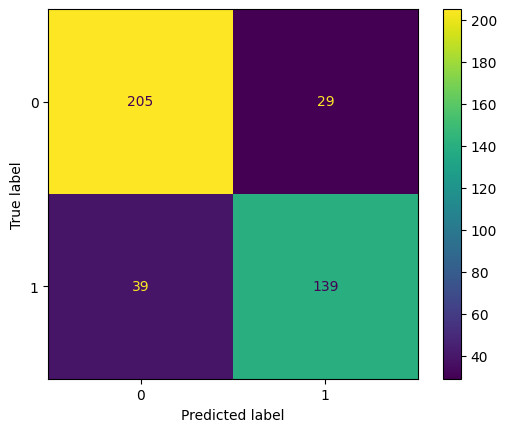

In [166]:
from sklearn import tree
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split, cross_validate
import numpy as np

X = dataset.X
Y = dataset.Y

decision_tree = tree.DecisionTreeClassifier()
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3)
decision_tree.fit(X_train, Y_train)
Y_pred = decision_tree.predict(X_test)

ConfusionMatrixDisplay.from_predictions(Y_test, Y_pred);

def tp(Y_pred, Y_real):
    return np.sum((Y_pred == 1) & (Y_real == 1))

def tn(Y_pred, Y_real):
    return np.sum((Y_pred == 0) & (Y_real == 0))

def fp(Y_pred, Y_real):
    return np.sum((Y_pred == 1) & (Y_real == 0))

def fn(Y_pred, Y_real):
    return np.sum((Y_pred == 0) & (Y_real == 1))

def accuracy(Y_pred, Y_real):
    return (tp(Y_pred, Y_real) + tn(Y_pred, Y_real)) / len(Y_real)

def specificity(Y_pred, Y_real):
    return tn(Y_pred, Y_real) / (tn(Y_pred, Y_real) + fp(Y_pred, Y_real))

def recall(Y_pred, Y_real):
    return tp(Y_pred, Y_real) / (tp(Y_pred, Y_real) + fn(Y_pred, Y_real))

def precision(Y_pred, Y_real):
    return tp(Y_pred, Y_real) / (tp(Y_pred, Y_real) + fp(Y_pred, Y_real))

print("Einzelner Split:")
for f in (accuracy, specificity, recall, precision):
    print(f"  {f.__name__}: {f(Y_pred, Y_test):.3f}")

scorers = dict()
scorers['accuracy']    = lambda clf, X, Y: accuracy(clf.predict(X), Y)
scorers['specificity'] = lambda clf, X, Y: specificity(clf.predict(X), Y)
scorers['recall']      = lambda clf, X, Y: recall(clf.predict(X), Y)
scorers['precision']   = lambda clf, X, Y: precision(clf.predict(X), Y)

cv = cross_validate(tree.DecisionTreeClassifier(), X, Y, cv=10, scoring=scorers)

print("\n10-fold Cross-Validation:")
for name in scorers:
    werte = cv["test_" + name]
    print(f"  {name}: Mean = {werte.mean():.3f}, Std = {werte.std():.3f}")